# 01 — Protocol repair and honest baselines

This notebook does the unglamorous but necessary part of the ZoomMoE plan:
rebuild the BreaKHis pipeline with **patient-disjoint** folds, then re-measure
the existing conditional-fusion baseline on data it has never seen.

What it produces:

1. A parsed dataframe with the **correct patient identifier** (the original
   notebook used `parts[1]`, the year field, which is not a patient id).
2. Multi-scale samples that keep incomplete magnification groups instead of
   dropping ~22% of the data.
3. Patient-disjoint 5-fold CV with an audited no-leak guarantee.
4. Four baselines: single-scale 40x, single-scale 400x, feature concat, and a
   faithful PyTorch port of the Keras conditional-fusion model.
5. A side-by-side of the **leaky protocol vs the honest protocol**, so the gap
   between the reported 96.09% and reality is measured rather than guessed.

Everything downstream (notebooks 02 and 03) reuses the folds built here.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import models

# breakhis_common.py must be importable: put it beside this notebook, or add it
# as a Kaggle utility script / dataset.
# Make breakhis_common.py importable
COMMON_DIR = "/kaggle/input/datasets/nabinkoirala452/code-files"

if COMMON_DIR not in sys.path:
    sys.path.insert(0, COMMON_DIR)

import breakhis_common as bc

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42
IMG_SIZE = 224
OUT = Path("artifacts")
OUT.mkdir(exist_ok=True)

bc.set_seed(SEED)
print("device:", DEVICE, "| torch:", torch.__version__)

device: cuda | torch: 2.10.0+cu128


## 1. Scan the dataset

The filename `SOB_B_TA-14-4659-40-001.png` decomposes as
`biopsy_class_subtype - year - slide - magnification - image`.
The patient (biopsy) is the whole prefix `SOB_B_TA-14-4659`, which is what
folds must be grouped by.

In [2]:
ROOT = bc.find_dataset_root()
print("dataset root:", ROOT)

df = bc.scan_breakhis(ROOT)
bc.dataset_summary(df)
df.head()

dataset root: /kaggle/input/datasets/ambarish/breakhis/BreaKHis_v1/BreaKHis_v1
images            : 7909
patients (biopsies): 82
  benign           : 24
  malignant        : 58
tumour subtypes    : ['A', 'DC', 'F', 'LC', 'MC', 'PC', 'PT', 'TA']

images per magnification / class:
label    0     1
mag             
40     625  1370
100    644  1437
200    623  1390
400    588  1232


,filepath,label,tumor_type,patient_id,mag,image_id
0,/kaggle/input/datasets/ambarish/breakhis/BreaK...,0,A,SOB_B_A-14-29960CD,200,12
1,/kaggle/input/datasets/ambarish/breakhis/BreaK...,0,A,SOB_B_A-14-29960CD,200,9
2,/kaggle/input/datasets/ambarish/breakhis/BreaK...,0,A,SOB_B_A-14-29960CD,200,6
3,/kaggle/input/datasets/ambarish/breakhis/BreaK...,0,A,SOB_B_A-14-29960CD,200,11
4,/kaggle/input/datasets/ambarish/breakhis/BreaK...,0,A,SOB_B_A-14-29960CD,200,4


### Why the original patient id was wrong

If this prints a small number on the left and ~82 on the right, the original
random split was almost certainly putting the same patient in train and test.

In [3]:
orig_style = df["filepath"].map(lambda p: Path(p).stem.split("-")[1])
print("distinct groups using parts[1] (original) :", orig_style.nunique())
print("distinct groups using full biopsy prefix   :", df.patient_id.nunique())

distinct groups using parts[1] (original) : 2
distinct groups using full biopsy prefix   : 82


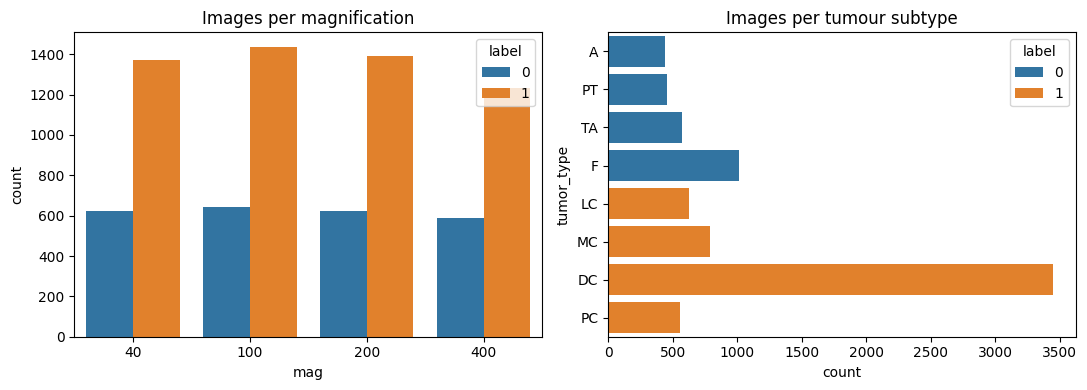

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="mag", hue="label", ax=ax[0])
ax[0].set_title("Images per magnification")
sns.countplot(data=df, y="tumor_type", hue="label", ax=ax[1])
ax[1].set_title("Images per tumour subtype")
plt.tight_layout()
plt.savefig(OUT / "fig_distribution.png", dpi=150)
plt.show()

## 2. Group into multi-scale samples

Two grouping modes, both kept so the effect can be ablated later:

* `image_id` — reproduces the baseline pairing (image 001 at 40x with image
  001 at 400x). Convenient, but those are **not** the same field of view.
* `pool` — candidates for each magnification are every image of that patient
  at that magnification, and one is drawn at random per epoch. This is honest
  about the lack of registration and doubles as augmentation.

In [5]:
samples_full = bc.build_groups(df, pair_mode="image_id", drop_incomplete=True)
samples_all = bc.build_groups(df, pair_mode="image_id", drop_incomplete=False)
samples_pool = bc.build_groups(df, pair_mode="pool", drop_incomplete=False)

print(f"complete 4-magnification groups only : {len(samples_full)}  (baseline used this)")
print(f"all groups, variable length          : {len(samples_all)}")
print("magnifications available per sample:")
print(samples_all.n_mags.value_counts().sort_index())

complete 4-magnification groups only : 1558  (baseline used this)
all groups, variable length          : 2407
magnifications available per sample:
n_mags
1     314
2     242
3     293
4    1558
Name: count, dtype: int64


## 3. Patient-disjoint folds

`audit_folds` asserts that no patient id appears in two splits of the same
fold. If this cell raises, stop and fix it before running anything else.

In [6]:
folds = bc.make_folds(samples_all, n_splits=5, val_frac=0.15, seed=SEED)
bc.audit_folds(samples_all, folds)

# folds over the complete-groups subset, for like-for-like baseline comparison
folds_full = bc.make_folds(samples_full, n_splits=5, val_frac=0.15, seed=SEED)
bc.audit_folds(samples_full, folds_full)

np.save(OUT / "folds_all.npy", np.array(folds, dtype=object), allow_pickle=True)
np.save(OUT / "folds_full.npy", np.array(folds_full, dtype=object), allow_pickle=True)
samples_all.to_pickle(OUT / "samples_all.pkl")
samples_full.to_pickle(OUT / "samples_full.pkl")
samples_pool.to_pickle(OUT / "samples_pool.pkl")
print("saved folds and sample tables to", OUT)

fold 0: n={'train': 1638, 'val': 308, 'test': 461}  patients={'train': 56, 'val': 10, 'test': 16}  malignant frac={'train': 0.715, 'val': 0.529, 'test': 0.753}
fold 1: n={'train': 1707, 'val': 309, 'test': 391}  patients={'train': 56, 'val': 10, 'test': 16}  malignant frac={'train': 0.733, 'val': 0.443, 'test': 0.749}
fold 2: n={'train': 1622, 'val': 283, 'test': 502}  patients={'train': 56, 'val': 10, 'test': 16}  malignant frac={'train': 0.709, 'val': 0.47, 'test': 0.793}
fold 3: n={'train': 1652, 'val': 233, 'test': 522}  patients={'train': 55, 'val': 10, 'test': 17}  malignant frac={'train': 0.712, 'val': 0.545, 'test': 0.722}
fold 4: n={'train': 1608, 'val': 268, 'test': 531}  patients={'train': 55, 'val': 10, 'test': 17}  malignant frac={'train': 0.774, 'val': 0.634, 'test': 0.501}
fold 0: n={'train': 1037, 'val': 229, 'test': 292}  patients={'train': 54, 'val': 10, 'test': 17}  malignant frac={'train': 0.706, 'val': 0.472, 'test': 0.705}
fold 1: n={'train': 1037, 'val': 196, 'te

## 4. Precompute frozen VGG16 features

Every baseline here uses a frozen encoder, so the features are computed once
and cached. This makes the whole baseline sweep run in seconds instead of
hours. Notebook 02 works from raw pixels because ZoomMoE fine-tunes.

In [7]:
@torch.no_grad()
def precompute_vgg_features(paths, batch_size=64, img_size=224):
    from PIL import Image

    tf = bc.build_transforms(img_size, train=False)
    vgg = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1).features
    vgg = vgg.eval().to(DEVICE)

    cache, buf, keys = {}, [], []

    def flush():
        if not buf:
            return
        x = torch.stack(buf).to(DEVICE)
        f = vgg(x).mean(dim=(2, 3))  # global average pool -> 512-d
        for k, v in zip(keys, f.cpu().numpy().astype(np.float32)):
            cache[k] = v
        buf.clear()
        keys.clear()

    t0 = time.time()
    for i, p in enumerate(paths):
        buf.append(tf(Image.open(p).convert("RGB")))
        keys.append(p)
        if len(buf) == batch_size:
            flush()
        if i % 2000 == 0:
            print(f"  {i}/{len(paths)}  ({time.time() - t0:.0f}s)", flush=True)
    flush()
    vgg.cpu()
    torch.cuda.empty_cache()
    return cache


cache_path = OUT / "vgg16_features.npz"
if cache_path.exists():
    z = np.load(cache_path)
    feat_cache = {k: z[k] for k in z.files}
    print("loaded cached features:", len(feat_cache))
else:
    feat_cache = precompute_vgg_features(df.filepath.tolist())
    np.savez_compressed(cache_path, **feat_cache)
    print("computed and cached features:", len(feat_cache))

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 202MB/s]


  0/7909  (0s)
  2000/7909  (55s)
  4000/7909  (109s)
  6000/7909  (166s)
computed and cached features: 7909


## 5. Baseline models

`ConditionalFusion` is a faithful port of the Keras baseline: magnification
embedding concatenated to each 512-d feature, a dense projection to 256, one
4-head self-attention layer over the four tokens with a residual, mean pool,
128-d embedding, sigmoid. The only additions are a padding mask so incomplete
samples are handled, and an exposed `embedding` for t-SNE.

In [8]:
class SingleScale(nn.Module):
    """Baseline: one magnification only."""

    def __init__(self, mag_index, feat_dim=512, hid=256):
        super().__init__()
        self.mag_index = mag_index
        self.net = nn.Sequential(
            nn.Linear(feat_dim, hid), nn.ReLU(), nn.Dropout(0.3), nn.Linear(hid, 1)
        )

    def forward(self, feats, mask):
        return self.net(feats[:, self.mag_index]).squeeze(-1)


class ConcatMLP(nn.Module):
    """Baseline: concatenate all four magnifications, zeros where missing."""

    def __init__(self, feat_dim=512, n_mags=4, hid=512):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(feat_dim * n_mags, hid), nn.ReLU(), nn.Dropout(0.4), nn.Linear(hid, 1)
        )

    def forward(self, feats, mask):
        x = feats * mask.unsqueeze(-1).float()
        return self.net(x.flatten(1)).squeeze(-1)


class ConditionalFusion(nn.Module):
    """PyTorch port of the Keras multi-head conditional fusion baseline."""

    def __init__(self, feat_dim=512, n_mags=4, mag_dim=32, hid=256, heads=4, emb=128):
        super().__init__()
        self.mag_emb = nn.Embedding(n_mags, mag_dim)
        self.proj = nn.Sequential(nn.Linear(feat_dim + mag_dim, hid), nn.ReLU(), nn.Dropout(0.30))
        self.attn = nn.MultiheadAttention(hid, heads, batch_first=True)
        self.embed = nn.Sequential(nn.Linear(hid, emb), nn.ReLU(), nn.Dropout(0.40))
        self.head = nn.Linear(emb, 1)
        self.register_buffer("mag_ids", torch.arange(n_mags))

    def forward(self, feats, mask, return_embedding=False):
        B, M, _ = feats.shape
        e = self.mag_emb(self.mag_ids).unsqueeze(0).expand(B, -1, -1)
        tokens = self.proj(torch.cat([feats, e], dim=-1))

        pad = ~mask
        # a fully padded row would produce NaNs; keep at least one valid slot
        pad = pad & ~(pad.all(dim=1, keepdim=True))
        a, _ = self.attn(tokens, tokens, tokens, key_padding_mask=pad)
        fused = tokens + a

        w = mask.unsqueeze(-1).float()
        pooled = (fused * w).sum(1) / w.sum(1).clamp(min=1.0)
        z = self.embed(pooled)
        logit = self.head(z).squeeze(-1)
        return (logit, z) if return_embedding else logit


print(
    "params  single:",
    bc.count_params(SingleScale(0)),
    "| concat:",
    bc.count_params(ConcatMLP()),
    "| fusion:",
    bc.count_params(ConditionalFusion()),
)

params  single: 131585 | concat: 1049601 | fusion: 435841


## 6. Train / evaluate loop

Model selection on the validation fold by AUC; the test fold is scored once,
with the best validation checkpoint. No prediction is ever made on data the
model trained on.

In [9]:
def run_epoch(model, loader, optimiser=None, pos_weight=None):
    train = optimiser is not None
    model.train(train)
    losses, probs, ys, pids = [], [], [], []

    for batch in loader:
        feats = batch["feats"].to(DEVICE)
        mask = batch["mask"].to(DEVICE)
        y = batch["label"].to(DEVICE)

        with torch.set_grad_enabled(train):
            logit = model(feats, mask)
            loss = F.binary_cross_entropy_with_logits(logit, y, pos_weight=pos_weight)

        if train:
            optimiser.zero_grad()
            loss.backward()
            optimiser.step()

        losses.append(loss.item())
        probs.append(torch.sigmoid(logit).detach().cpu().numpy())
        ys.append(y.cpu().numpy())
        pids.append(batch["patient_idx"].numpy())

    return (
        float(np.mean(losses)),
        np.concatenate(probs),
        np.concatenate(ys),
        np.concatenate(pids),
    )
def run_baseline(model_fn, samples, folds, epochs=30, lr=1e-3, batch_size=64, tag=""):
    rows = []
    for fi, fold in enumerate(folds):
        bc.set_seed(SEED + fi)
        loaders = {
            k: DataLoader(
                bc.make_feature_dataset(samples.iloc[fold[k]], feat_cache),
                batch_size=batch_size,
                shuffle=(k == "train"),
                num_workers=2,
            )
            for k in ("train", "val", "test")
        }

        y_tr = samples.iloc[fold["train"]]["label"].values
        pw = torch.tensor([(y_tr == 0).sum() / max((y_tr == 1).sum(), 1)], device=DEVICE).float()

        model = model_fn().to(DEVICE)
        opt = torch.optim.Adam(model.parameters(), lr=lr)

        best_auc = -1.0
        # FIX 1: Initialize best_state so it is never None, even if AUC fails to improve
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

        for ep in range(epochs):
            run_epoch(model, loaders["train"], opt, pw)
            _, vp, vy, vpid = run_epoch(model, loaders["val"])
            vm = bc.evaluate(vy, vp, vpid)
            
            # FIX 2: Safely extract AUC and handle potential NaN values
            current_auc = vm.get("auc", 0.0)
            if current_auc is not None and not np.isnan(current_auc):
                if current_auc > best_auc:
                    best_auc = current_auc
                    best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

        model.load_state_dict(best_state)
        _, tp, ty, tpid = run_epoch(model, loaders["test"])
        m = bc.evaluate(ty, tp, tpid)
        m["fold"] = fi
        rows.append(m)
        print(f"  [{tag}] fold {fi}: " + "  ".join(f"{k}={v:.4f}" for k, v in m.items() if k != "fold"))

    return rows

## 7. Run the baselines (honest protocol)

In [10]:
EPOCHS = 30
results = {}

configs = {
    "single_40x": lambda: SingleScale(0),
    "single_400x": lambda: SingleScale(3),
    "concat_4scale": lambda: ConcatMLP(),
    "conditional_fusion": lambda: ConditionalFusion(),
}

for name, fn in configs.items():
    print(f"\n=== {name} (patient-disjoint) ===")
    results[name] = run_baseline(fn, samples_full, folds_full, epochs=EPOCHS, tag=name)

table = pd.DataFrame(
    {
        name: bc.summarise_folds(rows).apply(
            lambda r: f"{r['mean']:.4f} ± {r['std']:.4f}", axis=1
        )
        for name, rows in results.items()
    }
).T
table = table[["acc", "prr", "f1_macro", "auc"]]
table.columns = ["Image Acc", "Patient RR", "Macro-F1", "ROC-AUC"]
display(table)
table.to_csv(OUT / "baseline_results_honest.csv")


=== single_40x (patient-disjoint) ===
  [single_40x] fold 0: acc=0.8356  f1_macro=0.8107  prr=0.7707  auc=0.9299
  [single_40x] fold 1: acc=0.7508  f1_macro=0.7144  prr=0.7719  auc=0.7338
  [single_40x] fold 2: acc=0.7081  f1_macro=0.7016  prr=0.7261  auc=0.7868
  [single_40x] fold 3: acc=0.8689  f1_macro=0.7087  prr=0.8707  auc=0.8273
  [single_40x] fold 4: acc=0.8780  f1_macro=0.8458  prr=0.9006  auc=0.9822

=== single_400x (patient-disjoint) ===
  [single_400x] fold 0: acc=0.8836  f1_macro=0.8666  prr=0.8283  auc=0.9320
  [single_400x] fold 1: acc=0.7815  f1_macro=0.7616  prr=0.7817  auc=0.8556
  [single_400x] fold 2: acc=0.7688  f1_macro=0.7688  prr=0.8059  auc=0.8233
  [single_400x] fold 3: acc=0.8577  f1_macro=0.7206  prr=0.8639  auc=0.8896
  [single_400x] fold 4: acc=0.9177  f1_macro=0.8916  prr=0.9250  auc=0.9931

=== concat_4scale (patient-disjoint) ===
  [concat_4scale] fold 0: acc=0.9315  f1_macro=0.9192  prr=0.8793  auc=0.9843
  [concat_4scale] fold 1: acc=0.7538  f1_macro

,Image Acc,Patient RR,Macro-F1,ROC-AUC
single_40x,0.8083 ± 0.0752,0.8080 ± 0.0740,0.7562 ± 0.0670,0.8520 ± 0.1023
single_400x,0.8418 ± 0.0646,0.8410 ± 0.0559,0.8018 ± 0.0734,0.8987 ± 0.0664
concat_4scale,0.8639 ± 0.0940,0.8573 ± 0.0823,0.8154 ± 0.1289,0.9211 ± 0.0656
conditional_fusion,0.7161 ± 0.2801,0.7082 ± 0.2805,0.6969 ± 0.2704,0.9017 ± 0.0746


## 8. How much did the original protocol inflate the numbers?

Three protocols, same model:

* **leaky-random** — random split ignoring patient (what `validation_split`
  effectively did).
* **train-set** — fit on everything, predict on the same array. This is what
  produced the 96.09% / 99.86% in the current report.
* **honest** — patient-disjoint, held-out test fold.

In [11]:
def train_set_score(samples, epochs=EPOCHS):
    """Reproduce the reported number: evaluate on the training data itself."""
    bc.set_seed(SEED)
    ds = bc.make_feature_dataset(samples, feat_cache)
    loader = DataLoader(ds, batch_size=64, shuffle=True, num_workers=2)
    model = ConditionalFusion().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    for _ in range(epochs):
        run_epoch(model, loader, opt)
    evald = DataLoader(ds, batch_size=64, shuffle=False, num_workers=2)
    _, p, y, pid = run_epoch(model, evald)
    return bc.evaluate(y, p, pid)


leaky = bc.leaky_folds(samples_full, n_splits=5, seed=SEED)
print("\n=== conditional_fusion, leaky random split ===")
leaky_rows = run_baseline(ConditionalFusion, samples_full, leaky, epochs=EPOCHS, tag="leaky")

print("\n=== conditional_fusion, evaluated on training data ===")
train_row = train_set_score(samples_full)
print("  " + "  ".join(f"{k}={v:.4f}" for k, v in train_row.items()))

honest_mean = bc.summarise_folds(results["conditional_fusion"])["mean"]
leaky_mean = bc.summarise_folds(leaky_rows)["mean"]

comparison = pd.DataFrame(
    {
        "train-set (as reported)": pd.Series(train_row),
        "leaky random split": leaky_mean,
        "patient-disjoint (honest)": honest_mean,
    }
).loc[["acc", "prr", "f1_macro", "auc"]]
display(comparison.round(4))
comparison.to_csv(OUT / "protocol_comparison.csv")


=== conditional_fusion, leaky random split ===
  [leaky] fold 0: acc=0.3686  f1_macro=0.3638  prr=0.3521  auc=0.2893
  [leaky] fold 1: acc=0.3301  f1_macro=0.2482  prr=0.2949  auc=0.2586
  [leaky] fold 2: acc=0.3269  f1_macro=0.2464  prr=0.2895  auc=0.2508
  [leaky] fold 3: acc=0.4148  f1_macro=0.4116  prr=0.4241  auc=0.3443
  [leaky] fold 4: acc=0.6720  f1_macro=0.4019  prr=0.6974  auc=0.4190

=== conditional_fusion, evaluated on training data ===
  acc=1.0000  f1_macro=1.0000  prr=1.0000  auc=1.0000


,train-set (as reported),leaky random split,patient-disjoint (honest)
acc,1.0,0.4225,0.7161
prr,1.0,0.4116,0.7082
f1_macro,1.0,0.3344,0.6969
auc,1.0,0.3124,0.9017


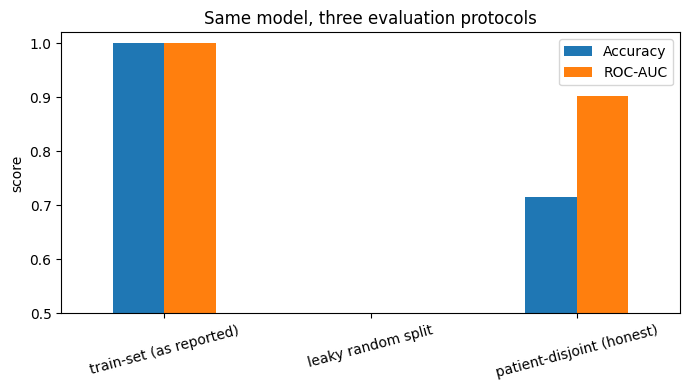

In [12]:
ax = comparison.T[["acc", "auc"]].plot(kind="bar", figsize=(7, 4), rot=15, ylim=(0.5, 1.02))
ax.set_ylabel("score")
ax.set_title("Same model, three evaluation protocols")
ax.legend(["Accuracy", "ROC-AUC"])
plt.tight_layout()
plt.savefig(OUT / "fig_protocol_gap.png", dpi=150)
plt.show()

The difference between these bars is the correction that belongs in the
progress report. It is not a failure of the model — it is the difference
between measuring fit and measuring generalisation.

## 9. Permutation sanity check on the baseline

The conditional-fusion model is permutation-invariant over magnifications by
construction, so shuffling the scale order at test time should change nothing
beyond the magnification embedding. Confirming that here establishes the
reference point that notebook 03 compares ZoomMoE against: if ZoomMoE is
genuinely modelling zoom as a process, its permuted score should drop and the
baseline's should not.

In [13]:
@torch.no_grad()
def permuted_score(model, samples, idx, n_perm=5):
    loader = DataLoader(
        bc.make_feature_dataset(samples.iloc[idx], feat_cache), batch_size=64, num_workers=2
    )
    model.eval()
    scores = []
    for t in range(n_perm):
        g = torch.Generator().manual_seed(SEED + t)
        probs, ys, pids = [], [], []
        for batch in loader:
            feats = batch["feats"].to(DEVICE)
            mask = batch["mask"].to(DEVICE)
            perm = torch.randperm(feats.shape[1], generator=g)
            logit = model(feats[:, perm], mask[:, perm])
            probs.append(torch.sigmoid(logit).cpu().numpy())
            ys.append(batch["label"].numpy())
            pids.append(batch["patient_idx"].numpy())
        scores.append(bc.evaluate(np.concatenate(ys), np.concatenate(probs), np.concatenate(pids)))
    return pd.DataFrame(scores).mean()


bc.set_seed(SEED)
fold0 = folds_full[0]
ds_tr = bc.make_feature_dataset(samples_full.iloc[fold0["train"]], feat_cache)
ldr = DataLoader(ds_tr, batch_size=64, shuffle=True, num_workers=2)
ref = ConditionalFusion().to(DEVICE)
opt = torch.optim.Adam(ref.parameters(), lr=1e-3)
for _ in range(EPOCHS):
    run_epoch(ref, ldr, opt)

_, p0, y0, pid0 = run_epoch(
    ref, DataLoader(bc.make_feature_dataset(samples_full.iloc[fold0["test"]], feat_cache), batch_size=64)
)
print("ordered   :", {k: round(v, 4) for k, v in bc.evaluate(y0, p0, pid0).items()})
print("permuted  :", permuted_score(ref, samples_full, fold0["test"]).round(4).to_dict())
torch.save(ref.state_dict(), OUT / "baseline_fusion_fold0.pt")

ordered   : {'acc': 0.8938, 'f1_macro': 0.8727, 'prr': 0.8394, 'auc': 0.9613}
permuted  : {'acc': 0.8795, 'f1_macro': 0.8523, 'prr': 0.8225, 'auc': 0.9564}


## 10. Handoff

Written to `artifacts/`:

| file | used by |
|---|---|
| `samples_all.pkl`, `samples_pool.pkl`, `samples_full.pkl` | 02, 03 |
| `folds_all.npy`, `folds_full.npy` | 02, 03 |
| `vgg16_features.npz` | 03 (t-SNE "before fusion") |
| `baseline_results_honest.csv`, `protocol_comparison.csv` | the report |
| `baseline_fusion_fold0.pt` | 03 (comparison curves) |

Next: `02_zoommoe_train.ipynb`.